### Setup: imports & paths


In [1]:
import os
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import image as mpimg

# Input CSVs (check: train path currently points to *test* CSV in your snippet)
csv_path_train = './Download/SignLengugeMNIST/sign_mnist_test/sign_mnist_test.csv'  # <-- likely should be .../sign_mnist_train.csv
csv_path_test  = './Download/SignLengugeMNIST/sign_mnist_test/sign_mnist_test.csv'

# Input dataset (ASL Alphabet)
ASL_TRAIN = './Download/ASLAlphabetDataset/asl_alphabet_train/asl_alphabet_train'
ASL_TEST  = './Download/ASLAlphabetDataset/asl_alphabet_test/asl_alphabet_test'

# Unified output root: one big dataset folder with train/test and subfolders per LETTER
out_root = './Dataset/SignLanguageMNIST_ASLAlphabet'
out_base_train = os.path.join(out_root, 'train')
out_base_test  = os.path.join(out_root, 'test')

os.makedirs(out_base_train, exist_ok=True)
os.makedirs(out_base_test, exist_ok=True)

# The 24 letters in Sign Language MNIST (J and Z are dynamic → excluded)
LETTERS_24 = ["A","B","C","D","E","F","G","H","I","K","L","M","N","O","P","Q","R","S","T","U","V","W","X","Y"]


### Utils: 

#### CSV -> PNG with label mapping

In [2]:
# %% [markdown]
# ### Utils: CSV -> PNG with label mapping (SignMNIST)

# %%
def load_sign_mnist(csv_path):
    """
    Loads Sign Language MNIST CSV: first col is label, 784 pixel values follow.
    Returns: labels (int array), pixels (uint8 array of shape [N, 784])
    """
    try:
        data = np.genfromtxt(csv_path, delimiter=',', skip_header=1)
    except Exception as e:
        raise RuntimeError(f'Failed to read CSV: {e}')
    if data.size == 0:
        raise RuntimeError('No data loaded from CSV - check the file path and format.')
    labels = data[:, 0].astype(int)
    pixels = data[:, 1:].astype(np.uint8)
    if pixels.shape[1] != 784:
        raise RuntimeError(f'Expected 784 pixels, got {pixels.shape[1]}')
    return labels, pixels

def build_label_to_letter_map(labels, letters=LETTERS_24):
    """
    Robust mapping: sort the unique label IDs found in the CSV
    and zip them to the ASL letters order (A..I,K..Y).
    """
    uniq = np.unique(labels)
    if len(uniq) != len(letters):
        raise RuntimeError(
            f'Found {len(uniq)} unique label IDs, expected {len(letters)}.\n'
            f'Unique label IDs: {list(map(int, uniq))}\n'
            f'Letters: {letters}'
        )
    uniq_sorted = np.sort(uniq)
    return {int(lab): letters[i] for i, lab in enumerate(uniq_sorted)}

def ensure_letter_dirs(base_dir, letters=LETTERS_24):
    for L in letters:
        os.makedirs(os.path.join(base_dir, L), exist_ok=True)

def save_split(csv_path, out_base, split_name):
    """
    Converts a CSV split to PNGs in letter-named folders (under out_base).
    Filenames: {split}_{LETTER}_{6-digit index}.png
    Also prints distribution info and writes a tiny mapping file.
    """
    labels, pixels = load_sign_mnist(csv_path)
    lab2letter = build_label_to_letter_map(labels)
    ensure_letter_dirs(out_base, LETTERS_24)

    # Distribution (quick check)
    uniq, counts = np.unique(labels, return_counts=True)
    print(f'[{split_name}] {pixels.shape[0]} images, {len(uniq)} classes.')
    for u, c in zip(uniq, counts):
        print(f'  id {int(u)} -> {lab2letter[int(u)]}: {c}')

    # Save images
    for i in range(pixels.shape[0]):
        lab = int(labels[i])
        letter = lab2letter[lab]
        img = pixels[i].reshape(28, 28)  # uint8 already
        out_dir = os.path.join(out_base, letter)
        fname = os.path.join(out_dir, f'{split_name}_{letter}_{i:06d}.png')
        plt.imsave(fname, img, cmap='gray', vmin=0, vmax=255)  # avoids autoscaling issues

    # Mapping file for reproducibility
    map_path = os.path.join(out_base, '_class_mapping.txt')
    with open(map_path, 'w') as f:
        f.write('label_id -> letter\n')
        for u in sorted(lab2letter.keys()):
            f.write(f'{u} -> {lab2letter[u]}\n')

    print(f'[{split_name}] Saved under: {out_base}')


#### JPG Color -> PNG GrayScale

In [ ]:
from PIL import Image

def convert_asl_split_to_gray(asl_src, out_base, split_name):
    """
    Converts ASL Alphabet images from RGB (JPG) to grayscale PNG.
    Saves inside the SAME Dataset/SignLanguageMNIST_ASLAlphabet/train|test folders, grouped by letter.
    Filenames: asl_{split}_{LETTER}_{6-digit index}.png
    (keeps original image size; no resize/downscale here)
    """
    total = 0
    for L in LETTERS_24:
        src_letter_dir = os.path.join(asl_src, L)
        dst_letter_dir = os.path.join(out_base, L)
        if not os.path.exists(src_letter_dir):
            print(f"[INFO] Missing folder for letter {L}: {src_letter_dir}")
            continue

        os.makedirs(dst_letter_dir, exist_ok=True)

        files = [f for f in os.listdir(src_letter_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.webp'))]
        for i, f in enumerate(sorted(files)):
            try:
                img_path = os.path.join(src_letter_dir, f)
                with Image.open(img_path) as img:
                    gray = img.convert('L')  # grayscale (8-bit)
                    fname = f"asl_{split_name}_{L}_{i:06d}.png"
                    gray.save(os.path.join(dst_letter_dir, fname))
                    total += 1
            except Exception as e:
                print(f"[ERROR] {img_path}: {e}")

    print(f"[ASL {split_name}] Saved {total} grayscale images under {out_base}")


### Transform Training and & Test Data

#### MNIST Dataset CSV to PNG

In [4]:
# ## Transform Training Split

save_split(csv_path_train, out_base_train, split_name='train')


# ## Transform Test Split

save_split(csv_path_test, out_base_test, split_name='test')


[train] 7172 images, 24 classes.
  id 0 -> A: 331
  id 1 -> B: 432
  id 2 -> C: 310
  id 3 -> D: 245
  id 4 -> E: 498
  id 5 -> F: 247
  id 6 -> G: 348
  id 7 -> H: 436
  id 8 -> I: 288
  id 10 -> K: 331
  id 11 -> L: 209
  id 12 -> M: 394
  id 13 -> N: 291
  id 14 -> O: 246
  id 15 -> P: 347
  id 16 -> Q: 164
  id 17 -> R: 144
  id 18 -> S: 246
  id 19 -> T: 248
  id 20 -> U: 266
  id 21 -> V: 346
  id 22 -> W: 206
  id 23 -> X: 267
  id 24 -> Y: 332
[train] Saved under: ./Dataset/SignLanguageMNIST_ASLAlphabet/train
[test] 7172 images, 24 classes.
  id 0 -> A: 331
  id 1 -> B: 432
  id 2 -> C: 310
  id 3 -> D: 245
  id 4 -> E: 498
  id 5 -> F: 247
  id 6 -> G: 348
  id 7 -> H: 436
  id 8 -> I: 288
  id 10 -> K: 331
  id 11 -> L: 209
  id 12 -> M: 394
  id 13 -> N: 291
  id 14 -> O: 246
  id 15 -> P: 347
  id 16 -> Q: 164
  id 17 -> R: 144
  id 18 -> S: 246
  id 19 -> T: 248
  id 20 -> U: 266
  id 21 -> V: 346
  id 22 -> W: 206
  id 23 -> X: 267
  id 24 -> Y: 332
[test] Saved under: ./

#### ASLAlphabet JPG RGB to PNG GrayScale

In [5]:
convert_asl_split_to_gray(ASL_TRAIN, out_base_train, 'train')
# convert_asl_split_to_gray(ASL_TEST,  out_base_test,  'test')

[ASL train] Saved 72000 grayscale images under ./Dataset/SignLanguageMNIST_ASLAlphabet/train


#### Preview Dataset

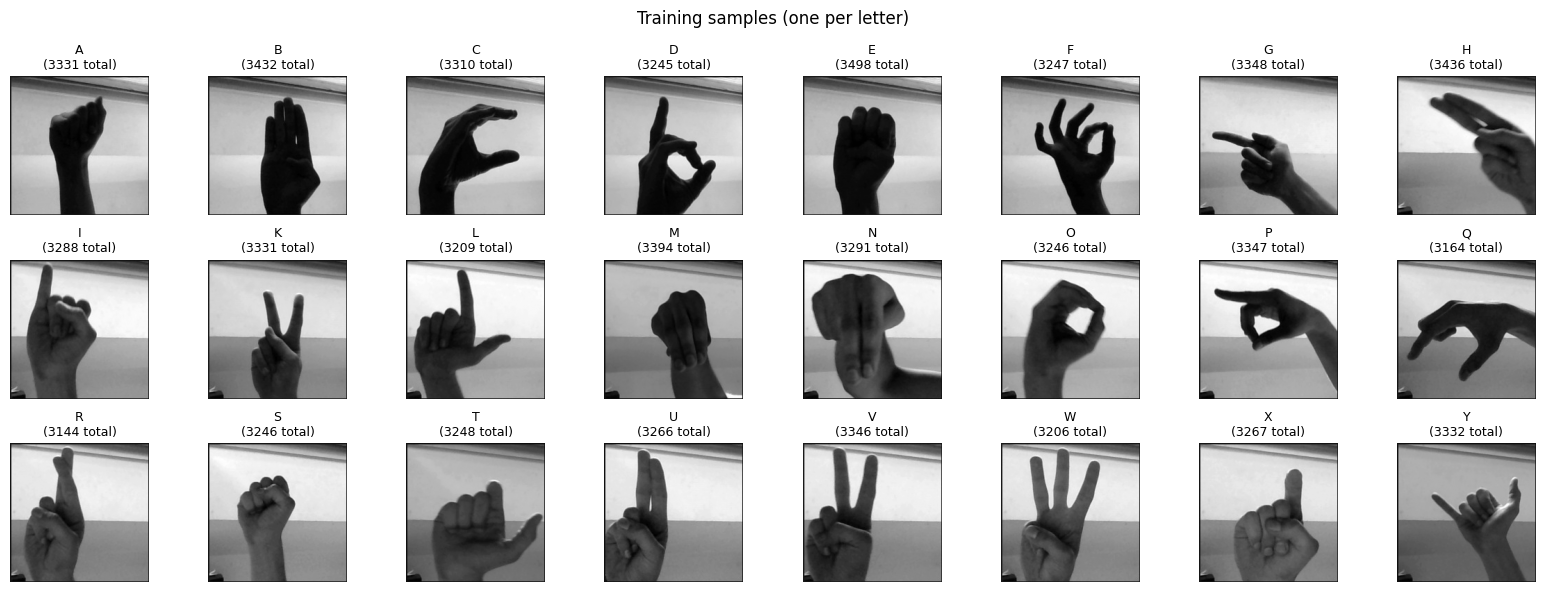

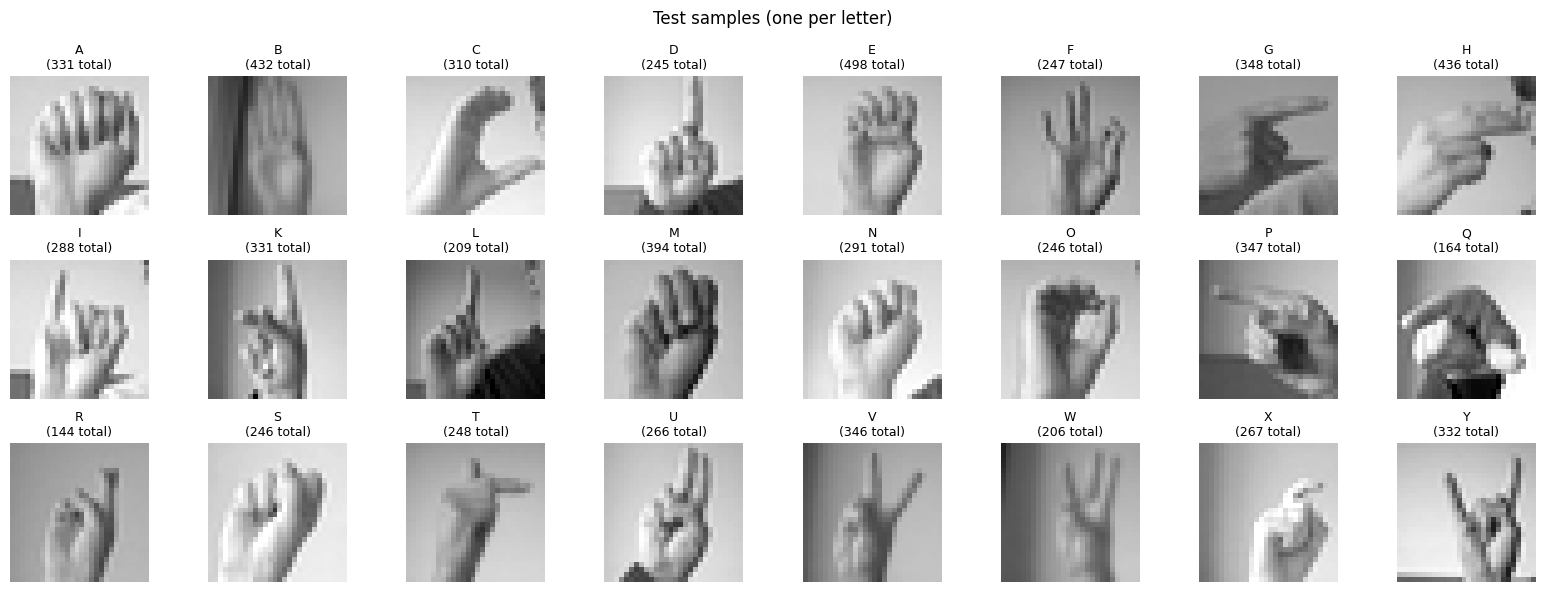

In [ ]:
def display_one_per_letter(out_base, title):
    letters = LETTERS_24
    num_labels = len(letters)
    cols = 8
    rows = (num_labels + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(2*cols, 2*rows))
    axes = axes.flatten()

    counts = []
    for L in letters:
        lab_dir = os.path.join(out_base, L)
        files = [f for f in os.listdir(lab_dir) if f.lower().endswith('.png')] if os.path.isdir(lab_dir) else []
        counts.append(len(files))

    for i, L in enumerate(letters):
        lab_dir = os.path.join(out_base, L)
        sample_file = None
        if os.path.isdir(lab_dir):
            # Prefer to show an ASL sample if present; else MNIST
            files_asl = sorted([f for f in os.listdir(lab_dir) if f.startswith('asl_') and f.lower().endswith('.png')])
            files_mni = sorted([f for f in os.listdir(lab_dir) if f.startswith('train_') or f.startswith('test_') and f.lower().endswith('.png')])
            pick = files_asl[0] if files_asl else (files_mni[0] if files_mni else None)
            if pick:
                sample_file = os.path.join(lab_dir, pick)

        if sample_file:
            img = mpimg.imread(sample_file)
            axes[i].imshow(img, cmap='gray')
        else:
            axes[i].text(0.5, 0.5, 'No image', ha='center', va='center')
            axes[i].set_facecolor('lightgray')

        axes[i].set_title(f'{L}\n({counts[i]} total)', fontsize=9)
        axes[i].axis('off')

    for j in range(num_labels, len(axes)):
        axes[j].axis('off')

    fig.suptitle(title, fontsize=12)
    plt.tight_layout()
    plt.show()

display_one_per_letter(out_base_train, 'Training samples (one per letter)')
display_one_per_letter(out_base_test,  'Test samples (one per letter)')
